# Binary Classification - Logistic Regression

- Iris Dataset

## Step 1: Import necessary libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize


## Step 2: Load the dataset

In [4]:
data = pd.read_csv("iris_binary_class.csv")

## Step 3: Exploratory Data Analysis (EDA)

In [5]:
# Display the first few rows of the dataset
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [24]:
# Summary statistics of the features
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,100.000000,100.000000,100.000000,100.000000
mean,5.471000,3.094000,2.862000,0.785000
std,0.641698,0.476057,1.448565,0.566288
min,4.300000,2.000000,1.000000,0.100000
25%,5.000000,2.800000,1.500000,0.200000
50%,5.400000,3.050000,2.450000,0.800000
75%,5.900000,3.400000,4.325000,1.300000
max,7.000000,4.400000,5.100000,1.800000


In [25]:
# Count of each class
data.value_counts()

sepal_length  sepal_width  petal_length  petal_width  species   
4.9           3.1          1.5           0.1          setosa        3
4.3           3.0          1.1           0.1          setosa        1
4.4           2.9          1.4           0.2          setosa        1
              3.0          1.3           0.2          setosa        1
4.5           2.3          1.3           0.3          setosa        1
                                                                   ..
6.7           3.1          4.4           1.4          versicolor    1
                           4.7           1.5          versicolor    1
6.8           2.8          4.8           1.4          versicolor    1
6.9           3.1          4.9           1.5          versicolor    1
7.0           3.2          4.7           1.4          versicolor    1
Name: count, Length: 98, dtype: int64

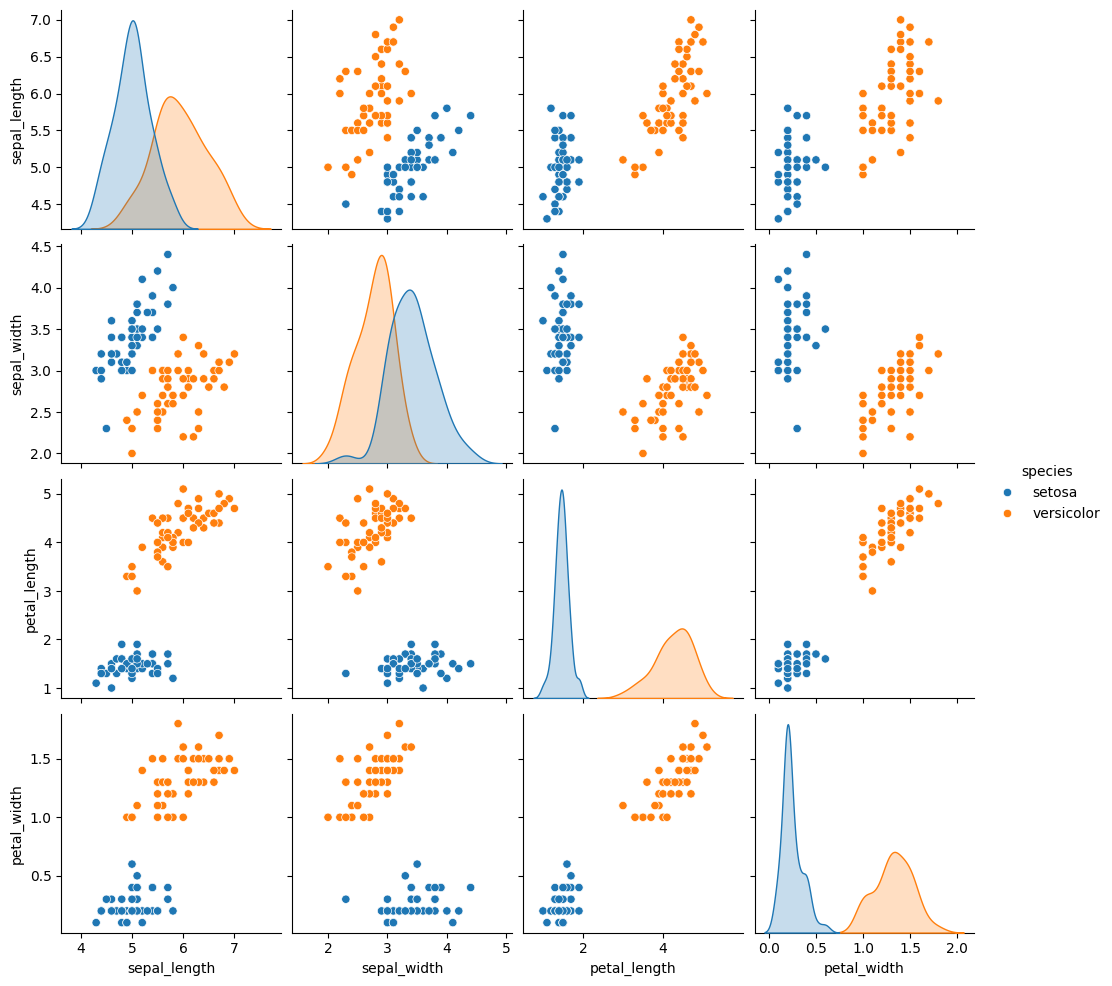

In [26]:
# Visualizations
# Pairplot to visualize relationships between features
sns.pairplot(data, hue="species")
plt.show()

## Step 4: Data Preprocessing

In [6]:
# Split the dataset into features (X) and target labels (y)
X = data.drop("species", axis=1)
y = data["species"]

In [7]:
# Encode the target variable into numeric labels
y_encoded = pd.factorize(y)[0]

In [8]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
# Standardize the features (important for logistic regression)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
print("Mean:\n", X_train.mean())
print("\nStandard Deviation:\n", X_train.std())

Mean:
 -1.2073675392798576e-16

Standard Deviation:
 1.0


In [12]:
print("Mean:\n", X_test.mean())
print("\nStandard Deviation:\n", X_test.std())

Mean:
 -0.009798335713164163

Standard Deviation:
 1.0576253864825884


## Step 5: Model Training

In [31]:
# Create and train a logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## Step 6: Model Evaluation


In [32]:
# Make predictions on the test set
y_pred = model.predict(X_test)

In [33]:
# Generate a classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [34]:
# Create a confusion matrix
confusion_mat = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(confusion_mat)

Confusion Matrix:
[[12  0]
 [ 0  8]]


## Step 7: Visualization 

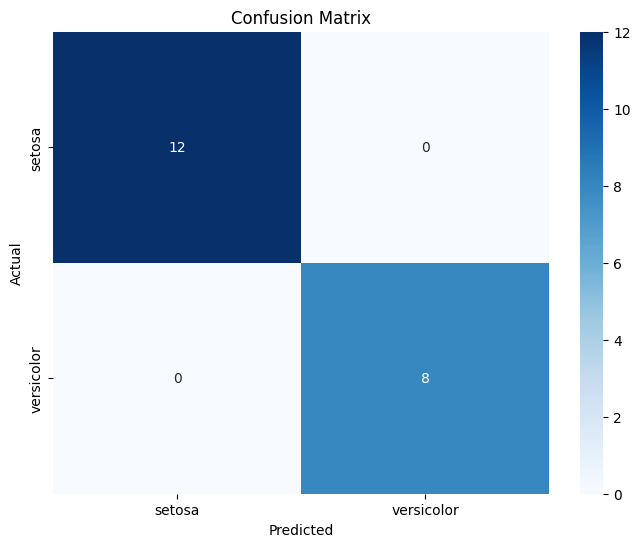

In [35]:
# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_mat, annot=True, cmap='Blues', fmt='d', xticklabels=data["species"].unique(),
            yticklabels=data["species"].unique())
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Step 8: ROC and AUC Visualization

In [36]:
# Binarize the labels for ROC calculation
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

In [37]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)


In [38]:
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_enc, y_prob)
roc_auc = auc(fpr, tpr)

print("ROC AUC:", roc_auc)


ROC AUC: 1.0


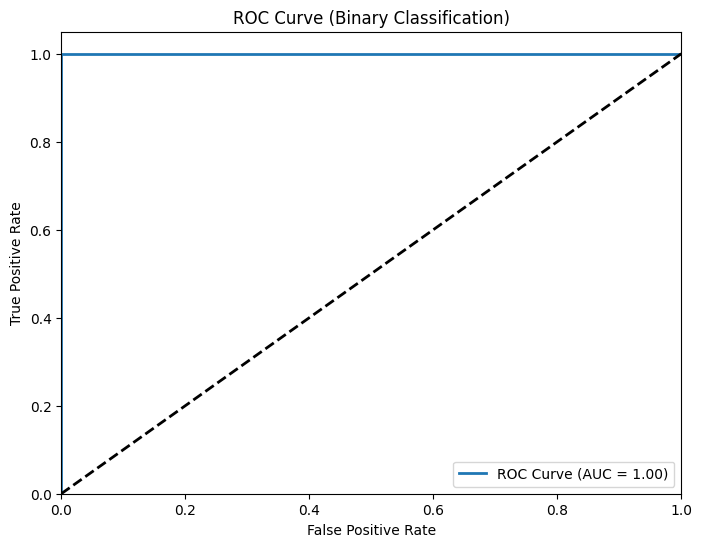

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    lw=2,
    label=f'ROC Curve (AUC = {roc_auc:.2f})'
)

plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Binary Classification)')
plt.legend(loc="lower right")
plt.show()


In [41]:
import numpy as np

user_input = np.array([[5.1, 3.5, 1.4, 0.2]])

pred_class = model.predict(user_input)[0]
pred_prob = model.predict_proba(user_input)[0]

print("Predicted Species:", pred_class)
print("Probabilities:")
print("Setosa     :", round(pred_prob[0], 2))
print("Versicolor :", round(pred_prob[1], 2))


Predicted Species: versicolor
Probabilities:
Setosa     : 0.04
Versicolor : 0.96
